<!-- Customer Analysis
l Total Customers
l Customers by Age Group
l Customers by Gender
l Customers by Occupation
l Customers by City
l Income Distribution -->

Customer Analysis
l Total Customers
l Customers by Age Group
l Customers by Gender
l Customers by Occupation
l Customers by City
l Income Distribution

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Load the dataset into a DataFrame.
data=pd.read_csv('customers.csv')

In [3]:
data.head()

,Customer_ID,Customer_Name,Age,Gender,Marital_Status,Occupation,City,Income
0,CUST_000001,Aryan Maharaj,58,Male,Single,Business Owner,Hyderabad,1236213
1,CUST_000002,Liam Chaudry,19,Male,Widowed,Self-Employed,Pune,2771559
2,CUST_000003,Azad Balan,40,Female,Divorced,Salaried,Pune,2549103
3,CUST_000004,Viraj Tiwari,20,Male,Divorced,Salaried,Hyderabad,723630
4,CUST_000005,Oni Kannan,58,Male,Married,Self-Employed,Pune,1891551


In [4]:
data.isnull().sum()

,0
Customer_ID,0
Customer_Name,0
Age,0
Gender,0
Marital_Status,0
Occupation,0
City,0
Income,0


In [5]:
# Drop rows that contain any NaN/null values
data.dropna(how='any', inplace=True)
data.reset_index(drop=True, inplace=True)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customer_ID     50000 non-null  object
 1   Customer_Name   50000 non-null  object
 2   Age             50000 non-null  int64 
 3   Gender          50000 non-null  object
 4   Marital_Status  50000 non-null  object
 5   Occupation      50000 non-null  object
 6   City            50000 non-null  object
 7   Income          50000 non-null  int64 
dtypes: int64(2), object(6)
memory usage: 3.1+ MB


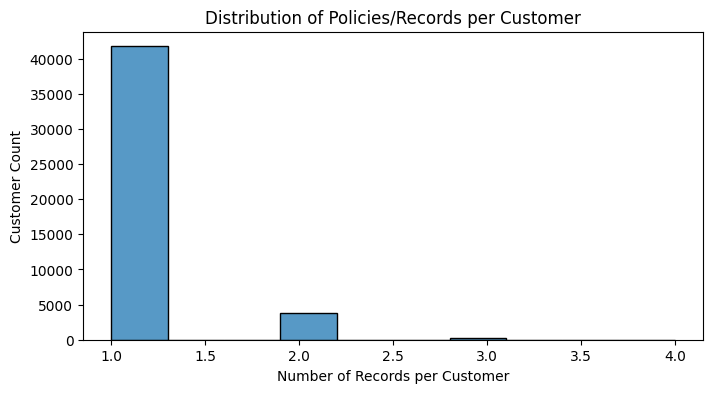

In [7]:
# Univariate Analysis
# Calculate how many times each customer appears
customer_counts = data['Customer_Name'].value_counts()

plt.figure(figsize=(8, 4))
sns.histplot(customer_counts, bins=10, kde=False)
plt.title("Distribution of Policies/Records per Customer")
plt.xlabel("Number of Records per Customer")
plt.ylabel("Customer Count")
plt.show()

/tmp/ipykernel_1072/702001378.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x='Age_Group', palette='Blues_d')


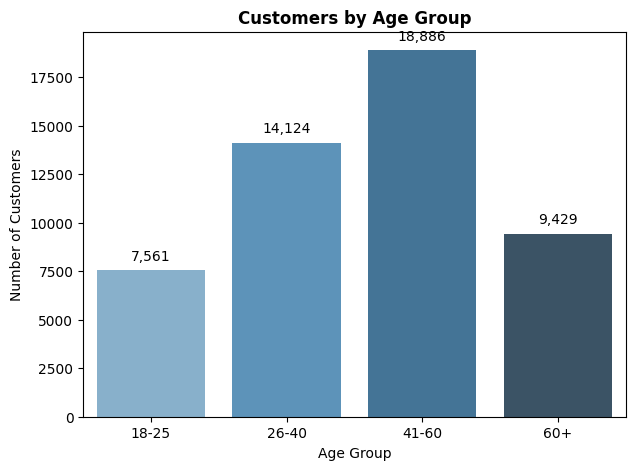

In [8]:
# 1. Feature Engineering: Bin continuous Age into discrete groups
bins = [0, 25, 40, 60, 100]
labels = ['18-25', '26-40', '41-60', '60+']
data['Age_Group'] = pd.cut(data['Age'], bins=bins, labels=labels)

# 2. Countplot of Age Groups
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=data, x='Age_Group', palette='Blues_d')

plt.title("Customers by Age Group", fontsize=12, fontweight="bold")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
# Annotate exact count on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')
plt.show()

/tmp/ipykernel_1072/1390942377.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x='Gender', palette='Blues_d')


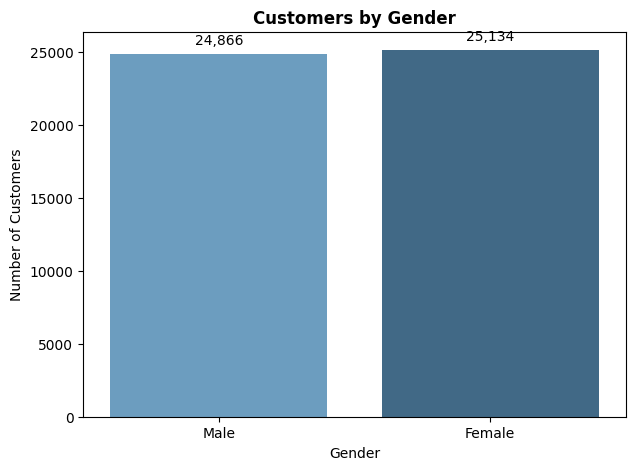

In [9]:
#Customers by Gender

#Countplot of Genders
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=data, x='Gender', palette='Blues_d')

plt.title("Customers by Gender", fontsize=12, fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
# Annotate exact count on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')
plt.show()

This loop places the exact numeric value above each individual bar in your Seaborn chart so you don't have to guess the numbers from the Y-axis.Here is the plain breakdown of every parameter and line:1. for p in ax.patches:ax.patches is a list containing all the individual rectangular bars rendered in your chart.p represents one bar at a time as the code loops through the chart from left to right.2. f'{int(p.get_height()):,}' — The Text to Displayp.get_height() fetches the bar's height, which corresponds to the customer count for that group.int(...) converts that count into an integer.:, adds comma separators to large numbers for readability (e.g., turning 12500 into 12,500).3. (p.get_x() + p.get_width() / 2., p.get_height()) — The Target CoordinatesThis tuple defines the Exact $(X, Y)$ Position on the plot where the label is anchored:X-coordinate (p.get_x() + p.get_width() / 2.): Finds the left edge of the bar (get_x()) and adds half the bar's width (get_width() / 2). This places the anchor precisely in the horizontal middle of the bar.Y-coordinate (p.get_height()): Places the anchor at the very top edge of the bar.4. Alignment & Offset Parametersha='center' (Horizontal Alignment): Centers the text horizontally over the $(X, Y)$ anchor point.va='bottom' (Vertical Alignment): Aligns the bottom edge of the text box to the anchor point, ensuring the text sits above the bar rather than inside it.xytext=(0, 5): Pushes the text 0 points horizontally and 5 points upward.textcoords='offset points': Instructs Matplotlib to treat xytext=(0, 5) as a pixel offset relative to the bar's top edge, creating a clean white space between the bar and the number.

/tmp/ipykernel_1072/514548757.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x='Occupation', palette='Reds_d')


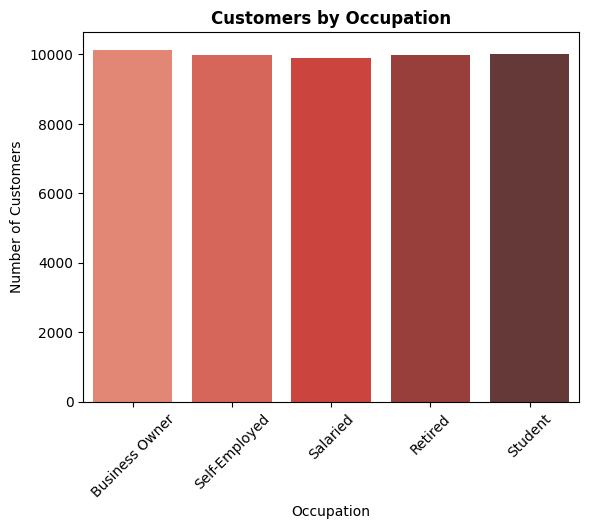

In [10]:
# Customers by Occupation
#Countplot by Occupations.
ax = sns.countplot(data=data, x='Occupation', palette='Reds_d')
plt.title("Customers by Occupation", fontsize=12, fontweight="bold")
plt.xlabel("Occupation")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

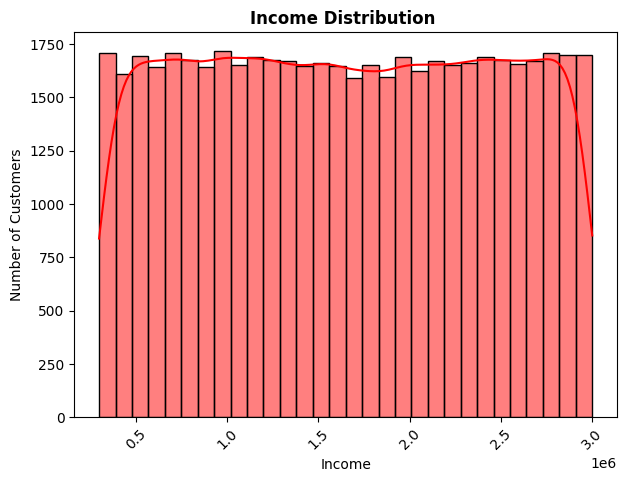

In [11]:
# Income Distribution
#Histplot for income hence its nuemerical value
plt.figure(figsize=(7,5))
ax = sns.histplot(data=data, x='Income',color='Red', kde=True, bins=30)
plt.title("Income Distribution ", fontsize=12, fontweight="bold")
plt.xlabel("Income")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

Policy Analysis
Total Policies
Active vs Expired Policies
Policies by Type
Premium by Policy Type
Coverage Amount Analysis





In [12]:
data_policies=pd.read_csv('policies.csv')

In [13]:
data_policies.head()

,Policy_ID,Customer_ID,Policy_Type,Policy_Start_Date,Policy_End_Date,Policy_Status,Coverage_Amount,Premium_Amount,Payment_Frequency
0,POL_000001,CUST_000001,Life,2023-01-31,2024-01-31,Expired,3639336,46820,Monthly
1,POL_000002,CUST_000002,Motor,2025-08-22,2026-08-22,Expired,3645146,87961,Quarterly
2,POL_000003,CUST_000003,Health,2021-10-19,2026-10-18,Active,761023,28414,Semi-Annual
3,POL_000004,CUST_000004,Home,2021-03-24,2024-03-23,Cancelled,3160434,54166,Semi-Annual
4,POL_000005,CUST_000005,Motor,2024-10-27,2026-10-27,Cancelled,2820280,129085,Monthly


In [14]:
data_policies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Policy_ID          50000 non-null  object
 1   Customer_ID        50000 non-null  object
 2   Policy_Type        50000 non-null  object
 3   Policy_Start_Date  50000 non-null  object
 4   Policy_End_Date    50000 non-null  object
 5   Policy_Status      50000 non-null  object
 6   Coverage_Amount    50000 non-null  int64 
 7   Premium_Amount     50000 non-null  int64 
 8   Payment_Frequency  50000 non-null  object
dtypes: int64(2), object(7)
memory usage: 3.4+ MB


In [15]:
# Drop rows that contain any NaN/null values
data_policies.dropna(how='any', inplace=True)
data.reset_index(drop=True, inplace=True)

/tmp/ipykernel_1072/2220404957.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data_policies, x='Policy_Type', palette='Set2')


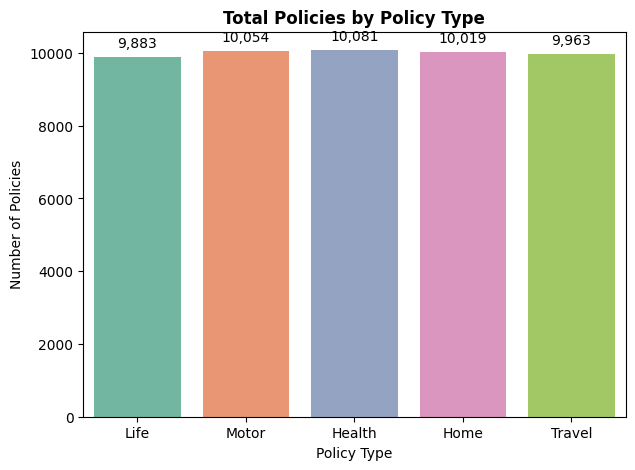

In [16]:
plt.figure(figsize=(7, 5))

# Plot counts of categorical features (e.g., Policy_Type)
ax = sns.countplot(data=data_policies, x='Policy_Type', palette='Set2')

plt.title("Total Policies by Policy Type", fontsize=12, fontweight="bold")
plt.xlabel("Policy Type")
plt.ylabel("Number of Policies")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()

/tmp/ipykernel_1072/197882202.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


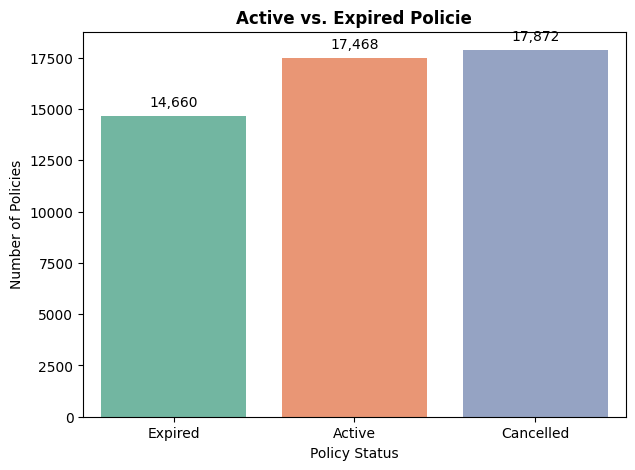

In [17]:
#Active vs Expired Policies
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=data_policies,
    x='Policy_Status',
    palette='Set2',
    legend=False
)

plt.title("Active vs. Expired Policie", fontsize=12, fontweight="bold")
plt.xlabel("Policy Status")
plt.ylabel("Number of Policies")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()

/tmp/ipykernel_1072/2150251014.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data_policies, x='Policy_Type', palette='Set2')


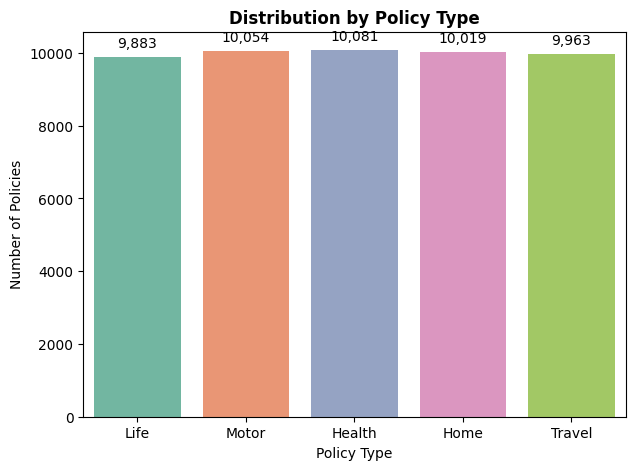

In [18]:
#Policies by Type
plt.figure(figsize=(7, 5))

# Plot counts of categorical features (e.g., Policy_Type)
ax = sns.countplot(data=data_policies, x='Policy_Type', palette='Set2')

plt.title("Distribution by Policy Type", fontsize=12, fontweight="bold")
plt.xlabel("Policy Type")
plt.ylabel("Number of Policies")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()

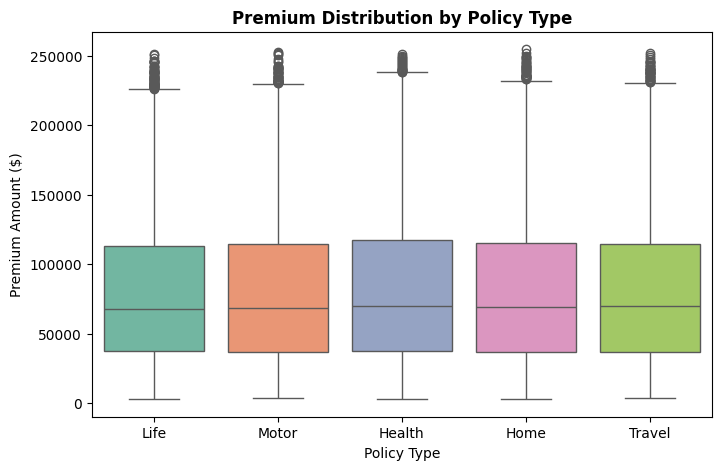

In [19]:
# Premium by Policy Type
plt.figure(figsize=(8, 5))

# Comparing continuous Premium_Amount across categorical Policy_Type
sns.boxplot(
    data=data_policies,
    x='Policy_Type',
    y='Premium_Amount',
    hue='Policy_Type',
    palette='Set2',
    legend=False
)

plt.title("Premium Distribution by Policy Type", fontsize=12, fontweight="bold")
plt.xlabel("Policy Type")
plt.ylabel("Premium Amount ($)")

plt.show()


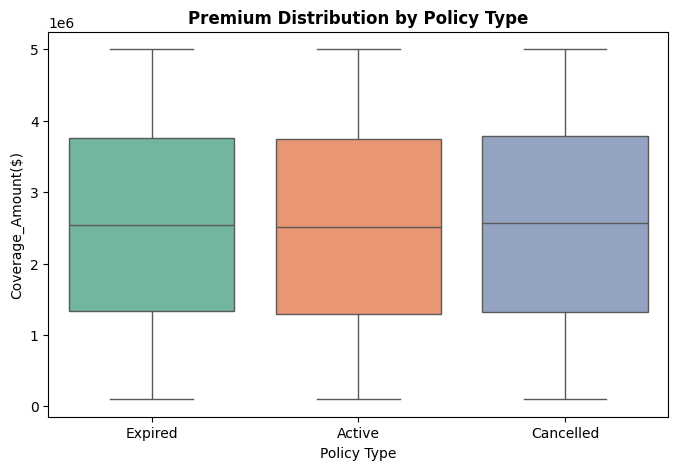

In [20]:
#Coverage Amount Analysis
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data_policies,
    x='Policy_Status',
    y='Coverage_Amount',
    hue='Policy_Status',
    palette='Set2',
    legend=False
)

plt.title("Premium Distribution by Policy Type", fontsize=12, fontweight="bold")
plt.xlabel("Policy Type")
plt.ylabel("Coverage_Amount($)")

plt.show()

Claims Analysis

In [21]:
data_claims=pd.read_csv('claims.csv')

In [22]:
data_claims.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35958 entries, 0 to 35957
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Claim_ID               35957 non-null  object
 1   Policy_ID              35958 non-null  object
 2   Claim_Date             35957 non-null  object
 3   Claim_Amount           35958 non-null  int64 
 4   Claim_Status           35958 non-null  object
 5   Claim_Type             35957 non-null  object
 6   Claim_Processing_Days  35958 non-null  int64 
dtypes: int64(2), object(5)
memory usage: 1.9+ MB


In [23]:
data_claims.head()

,Claim_ID,Policy_ID,Claim_Date,Claim_Amount,Claim_Status,Claim_Type,Claim_Processing_Days
0,NaN,POL_000001,NaN,0,No Claim,NaN,0
1,CLM_000002,POL_000002,2025-09-24,424428,Rejected,Natural Disaster,8
2,CLM_000004,POL_000004,2023-08-12,2082174,Approved,Accidental,40
3,CLM_000005,POL_000005,2026-01-27,719296,Approved,Theft,6
4,CLM_000007,POL_000007,2023-08-23,93100,Pending,Natural Disaster,10


In [24]:
# Drop rows that contain any NaN/null values
data_claims.dropna(how='any', inplace=True)
data.reset_index(drop=True, inplace=True)

/tmp/ipykernel_1072/4293263014.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=claims_per_policy, palette='Blues_d')


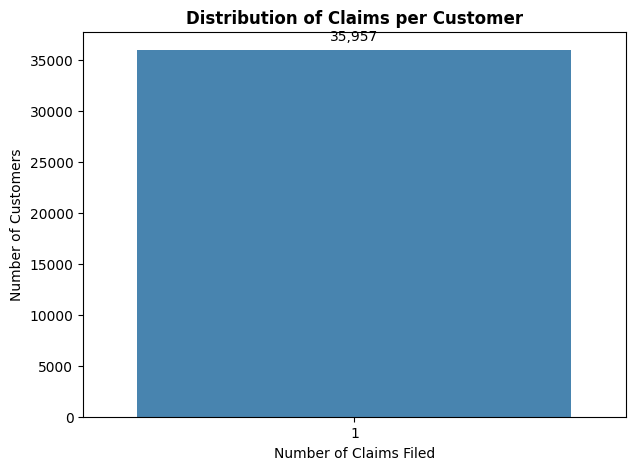

In [25]:
#Total Claims

# Count claims per POLICY
claims_per_policy = data_claims['Policy_ID'].value_counts()

plt.figure(figsize=(7, 5))
ax = sns.countplot(x=claims_per_policy, palette='Blues_d')

plt.title("Distribution of Claims per Customer", fontsize=12, fontweight="bold")
plt.xlabel("Number of Claims Filed")
plt.ylabel("Number of Customers")

# Annotate exact counts on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()

/tmp/ipykernel_1072/3447492832.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=approved_per_policy, palette='Blues_d')


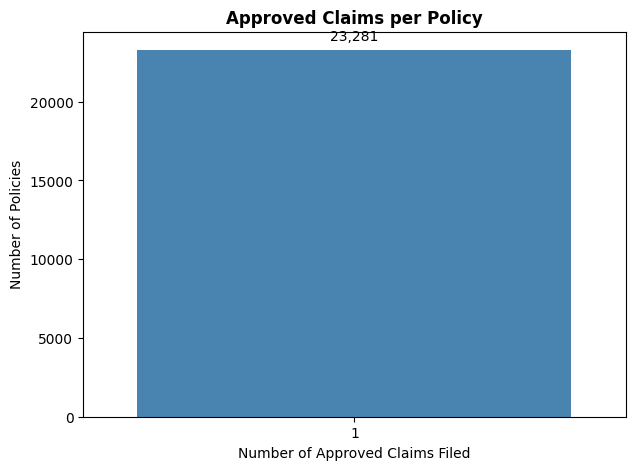

In [26]:
#Approved Claims

# 1. Filter dataset for approved claims only
approved_claims = data_claims[data_claims['Claim_Status'] == 'Approved']

# 2. Count approved claims per Policy_ID
approved_per_policy = approved_claims['Policy_ID'].value_counts()

# 3. Plot distribution of approved claims per policy
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=approved_per_policy, palette='Blues_d')

plt.title("Approved Claims per Policy", fontsize=12, fontweight="bold")
plt.xlabel("Number of Approved Claims Filed")
plt.ylabel("Number of Policies")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()


/tmp/ipykernel_1072/2981087222.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=rejected_per_policy, palette='Blues_d')


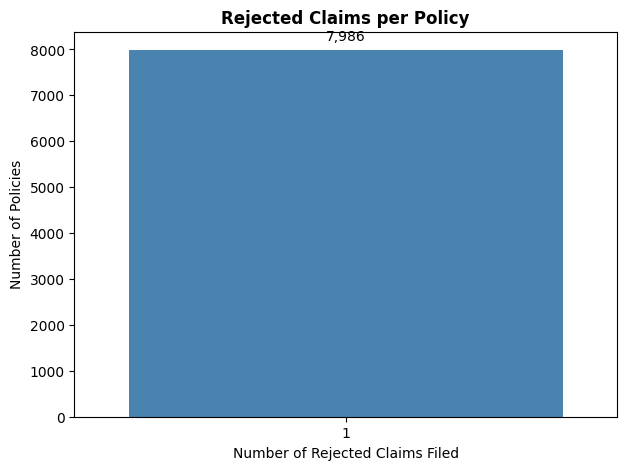

In [27]:
# Rejected Claims
# 1. Filter dataset for Rejected claims only
rejected_claims = data_claims[data_claims['Claim_Status'] == 'Rejected']

# 2. Count rejected claims per Policy_ID
rejected_per_policy = rejected_claims['Policy_ID'].value_counts()

# 3. Plot distribution of approved claims per policy
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=rejected_per_policy, palette='Blues_d')

plt.title("Rejected Claims per Policy", fontsize=12, fontweight="bold")
plt.xlabel("Number of Rejected Claims Filed")
plt.ylabel("Number of Policies")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()



/tmp/ipykernel_1072/2492761757.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=Pending_per_policy, palette='Blues_d')


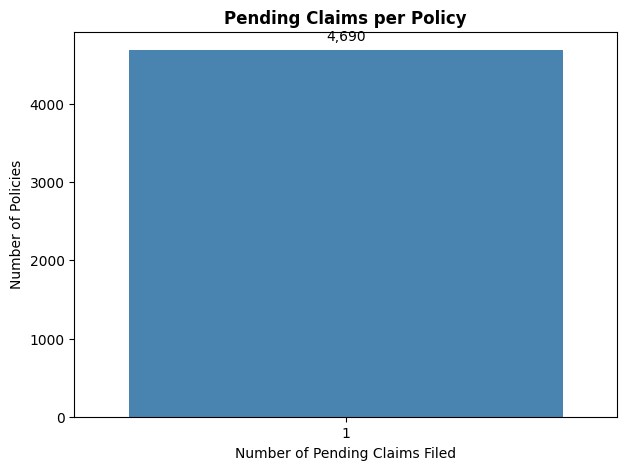

In [28]:
# Pending Claims
# 1. Filter dataset for Pending claims only
Pending_claims = data_claims[data_claims['Claim_Status'] == 'Pending']

# 2. Count Pending claims per Policy_ID
Pending_per_policy = Pending_claims['Policy_ID'].value_counts()

# 3. Plot distribution of Pending claims per policy
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=Pending_per_policy, palette='Blues_d')

plt.title("Pending Claims per Policy", fontsize=12, fontweight="bold")
plt.xlabel("Number of Pending Claims Filed")
plt.ylabel("Number of Policies")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()



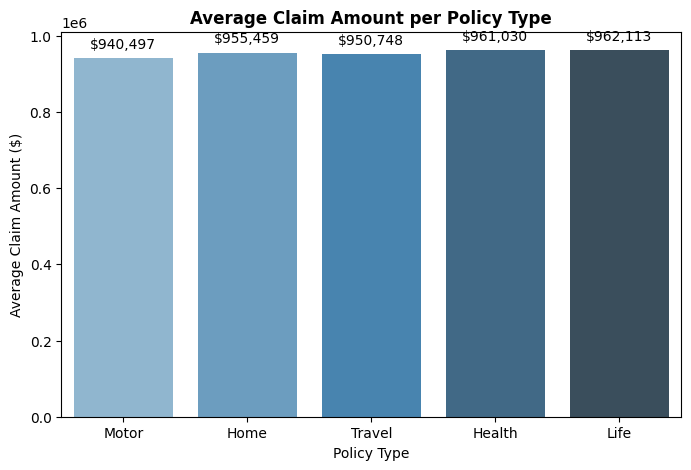

In [29]:
 #Claim Amount by Policy Type

# Merge claims with policies to link Policy_Type
claims_policies = pd.merge(data_claims, data_policies, on='Policy_ID', how='inner')

plt.figure(figsize=(8, 5))

# Calculate average Claim_Amount per Policy_Type
ax = sns.barplot(
    data=claims_policies,
    x='Policy_Type',
    y='Claim_Amount',
    hue='Policy_Type',
    palette='Blues_d',
    errorbar=None,
    legend=False
)

plt.title("Average Claim Amount per Policy Type", fontsize=12, fontweight="bold")
plt.xlabel("Policy Type")
plt.ylabel("Average Claim Amount ($)")

# Annotate exact mean values on top of bars
for p in ax.patches:
    ax.annotate(f'${int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()

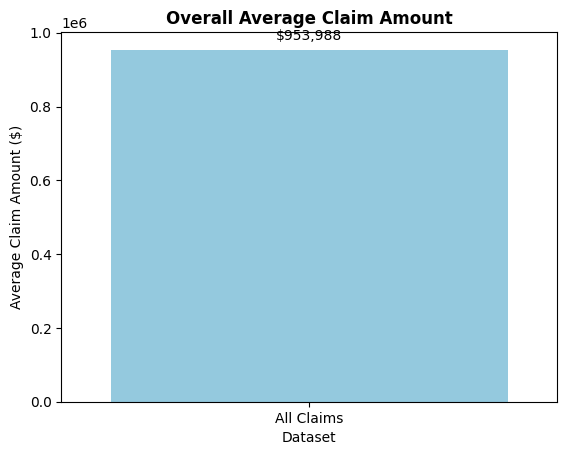

In [30]:
# Average Claim Amount

# Merge claims with policies to link Policy_Type
avg_claim = data_claims['Claim_Amount'].mean()

# Single bar chart plot
ax = sns.barplot(x=['All Claims'], y=[avg_claim], color='skyblue')

plt.title("Overall Average Claim Amount", fontsize=12, fontweight="bold")
plt.xlabel("Dataset")
plt.ylabel("Average Claim Amount ($)")

# Add exact value label on top of the single bar
for p in ax.patches:
    ax.annotate(f'${int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()





In [31]:
#Risk Analysis
#High-Risk Customers

data_risk = pd.read_csv('Risk_Info.csv')

In [32]:
data_risk.head()

,Transaction_ID,Customer_ID,Policy_ID,Risk_Level,Previous_Claims,Customer_Risk_Score
0,TXN_000001,CUST_000001,POL_000001,Low,0,7.19
1,TXN_000002,CUST_000002,POL_000002,High,4,91.94
2,TXN_000003,CUST_000003,POL_000003,Low,0,10.77
3,TXN_000004,CUST_000004,POL_000004,Low,0,17.10
4,TXN_000005,CUST_000005,POL_000005,Low,1,29.90


In [33]:
data_risk.tail()

,Transaction_ID,Customer_ID,Policy_ID,Risk_Level,Previous_Claims,Customer_Risk_Score
49995,TXN_049996,CUST_049996,POL_049996,High,2,65.17
49996,TXN_049997,CUST_049997,POL_049997,Low,0,8.50
49997,TXN_049998,CUST_049998,POL_049998,High,2,64.26
49998,TXN_049999,CUST_049999,POL_049999,Low,0,18.49
49999,TXN_050000,CUST_050000,POL_050000,Medium,1,48.71


#High - Risk Customers

/tmp/ipykernel_1072/965263511.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=Risklevelhigh, palette='Blues_d')


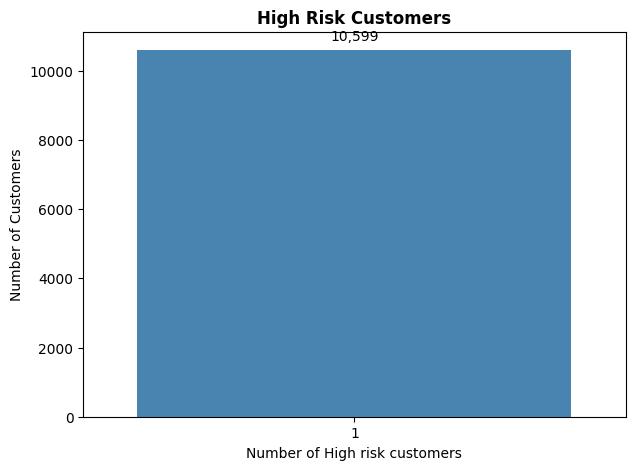

In [34]:
#High - Risk Customers

# 1. Filter dataset for High-Risk claims only
Risk_lev = data_risk[data_risk['Risk_Level'] == 'High']

# 2. Count the high risk level customer id
Risklevelhigh = Risk_lev['Customer_ID'].value_counts()

# 3. Plot distribution of high level customers
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=Risklevelhigh, palette='Blues_d')

plt.title("High Risk Customers", fontsize=12, fontweight="bold")
plt.xlabel("Number of High risk customers")
plt.ylabel("Number of Customers")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()




#Medium-Risk Customers

/tmp/ipykernel_1072/71375124.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=Risklevelhigh, palette='Blues_d')


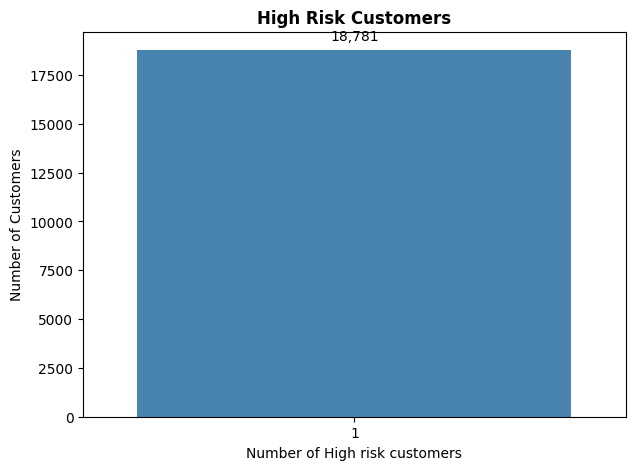

In [35]:

# 1. Filter dataset for High-Risk claims only
Risk_lev = data_risk[data_risk['Risk_Level'] == 'Medium']

# 2. Count the high risk level customer id
Risklevelhigh = Risk_lev['Customer_ID'].value_counts()

# 3. Plot distribution of high level customers
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=Risklevelhigh, palette='Blues_d')

plt.title("High Risk Customers", fontsize=12, fontweight="bold")
plt.xlabel("Number of High risk customers")
plt.ylabel("Number of Customers")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()



#Low-Risk Customers

/tmp/ipykernel_1072/1302217072.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=Risklevelhigh, palette='Blues_d')


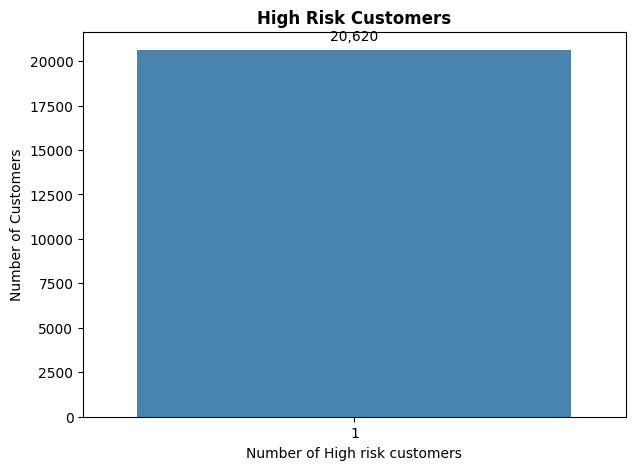

In [36]:
# 1. Filter dataset for High-Risk claims only
Risk_lev = data_risk[data_risk['Risk_Level'] == 'Low']

# 2. Count the high risk level customer id
Risklevelhigh = Risk_lev['Customer_ID'].value_counts()

# 3. Plot distribution of high level customers
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=Risklevelhigh, palette='Blues_d')

plt.title("High Risk Customers", fontsize=12, fontweight="bold")
plt.xlabel("Number of High risk customers")
plt.ylabel("Number of Customers")

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()


#Risk by Age Group

/tmp/ipykernel_1072/501252728.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Risk Level", bbox_to_anchor=(1.05, 1), loc='upper left')


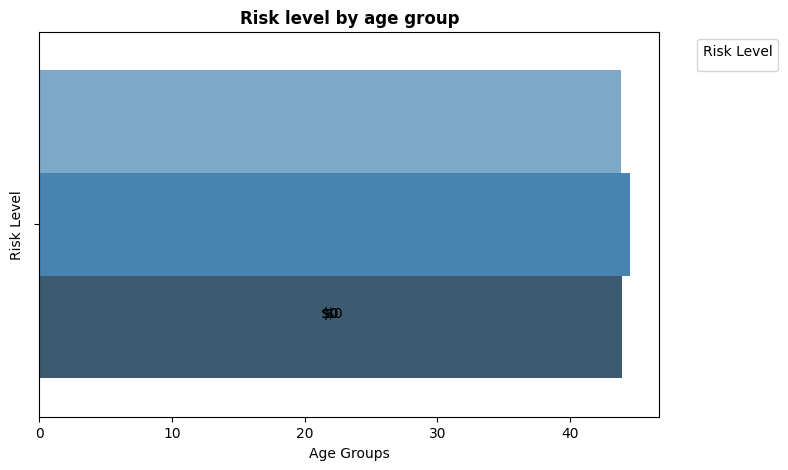

In [37]:
#Merge risk and customer data on customer id
Risk_by_age_group = pd.merge(data_risk,data, on='Customer_ID', how='inner')

plt.figure(figsize=(8, 5))

#Calculate Risk per age group

ax = sns.barplot(
    data=Risk_by_age_group,
    x='Age',
    hue='Risk_Level',
    palette='Blues_d',
    errorbar=None,
    legend=False
)

plt.title("Risk level by age group", fontsize=12, fontweight="bold")
plt.xlabel("Age Groups")
plt.ylabel("Risk Level")
plt.legend(title="Risk Level", bbox_to_anchor=(1.05, 1), loc='upper left')

# Annotate exact mean values on top of bars
for p in ax.patches:
    ax.annotate(f'${int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()

 #Risk by Policy Type

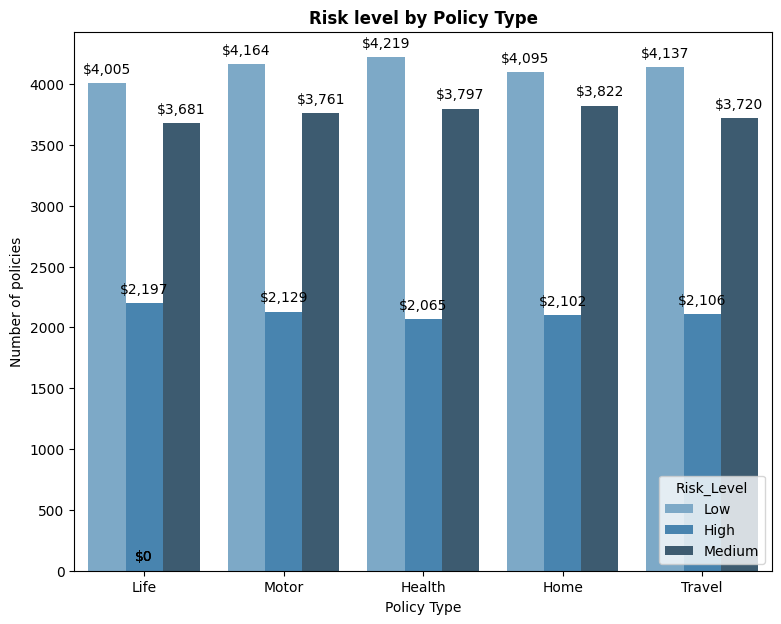

In [38]:
#Merge risk and policy data on customer id
Risk_by_policy_type = pd.merge(data_risk,data_policies, on='Customer_ID', how='inner')

plt.figure(figsize=(9, 7))

#Calculate Risk per policy type

ax = sns.countplot(
    data=Risk_by_policy_type,  # Correct dataframe variable name
    x='Policy_Type',
    hue='Risk_Level',
    palette='Blues_d'
)

plt.title("Risk level by Policy Type", fontsize=12, fontweight="bold")
plt.xlabel("Policy Type")
plt.ylabel("Number of policies")

# Annotate exact mean values on top of bars
for p in ax.patches:
    ax.annotate(f'${int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.show()

#Risk by Previous Claims

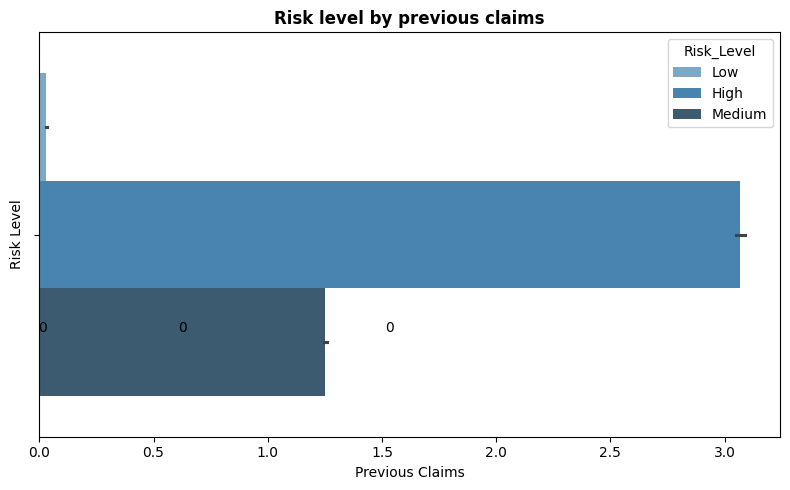

In [39]:
#Calculate Risk by previous claim

plt.figure(figsize=(8, 5))

#Calculate Risk per policy type
ax = sns.barplot(
    data=data_risk,
    x='Previous_Claims',
    hue='Risk_Level',
    palette='Blues_d'
)

plt.title("Risk level by previous claims", fontsize=12, fontweight="bold")
plt.xlabel("Previous Claims")
plt.ylabel("Risk Level")

for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Only annotate non-zero bars
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# Feature Engineering tasks

In [40]:
# 1. Map Risk_Level to numeric weights
risk_mapping = {'Low': 1, 'Medium': 2, 'High': 3}
data_risk['Risk_Weight'] = data_risk['Risk_Level'].map(risk_mapping)

# 2. Group by Customer_ID to calculate aggregated risk indicators
customer_risk_agg = data_risk.groupby('Customer_ID').agg(
    Avg_Risk_Weight=('Risk_Weight', 'mean'),
    Max_Previous_Claims=('Previous_Claims', 'max')
).reset_index()

# 3. Create a combined Customer Risk Score (e.g., 60% weight to risk level, 40% to claims)
customer_risk_agg['Customer_Risk_Score'] = (
    (customer_risk_agg['Avg_Risk_Weight'] * 0.6) +
    (customer_risk_agg['Max_Previous_Claims'] * 0.4)
)

# 4. Merge the new feature back into the main customer dataset (data)
data = pd.merge(data, customer_risk_agg[['Customer_ID', 'Customer_Risk_Score']], on='Customer_ID', how='left')

# Fill missing values with a baseline score if any customer has no risk record
data['Customer_Risk_Score'] = data['Customer_Risk_Score'].fillna(1.0)

# Preview the new feature
print(data[['Customer_ID', 'Customer_Risk_Score']].head())

   Customer_ID  Customer_Risk_Score
0  CUST_000001                  0.6
1  CUST_000002                  3.4
2  CUST_000003                  0.6
3  CUST_000004                  0.6
4  CUST_000005                  1.0


In [41]:
#Claim Frequency

# 1. Claims ko Policies ke sath merge karke Customer_ID nikalna
claims_with_policy = pd.merge(data_claims, data_policies[['Policy_ID', 'Customer_ID']], on='Policy_ID', how='inner')

# 2. Har customer ke total claims count karna (Claims Frequency)
claims_freq = claims_with_policy.groupby('Customer_ID').size().reset_index(name='Claims_Frequency')

# 3. Is naye feature ko main customer dataset (data) mein merge karna
data = pd.merge(data, claims_freq, on='Customer_ID', how='left')

# 4. Jin customers ka koi claim nahi hai, wahan 0 fill kar dena
data['Claims_Frequency'] = data['Claims_Frequency'].fillna(0).astype(int)

# Preview the new feature
print(data[['Customer_ID', 'Claims_Frequency']].head())

   Customer_ID  Claims_Frequency
0  CUST_000001                 0
1  CUST_000002                 1
2  CUST_000003                 0
3  CUST_000004                 1
4  CUST_000005                 1


In [42]:
# 1. Claims aur Policies ko merge karke Claim_Amount aur Premium_Amount ko ek jagah lana
claim_policy_merged = pd.merge(data_claims, data_policies[['Policy_ID', 'Premium_Amount']], on='Policy_ID', how='inner')

# 2. Calculate Claim-to-Premium Ratio
claim_policy_merged['Claim_To_Premium_Ratio'] = claim_policy_merged['Claim_Amount'] / claim_policy_merged['Premium_Amount']

# 3. Agar ek policy ke multiple claims hain, toh unka average ratio nikalna
policy_ratio = claim_policy_merged.groupby('Policy_ID')['Claim_To_Premium_Ratio'].mean().reset_index()

# 4. Is naye feature ko data_policies mein merge karna
data_policies = pd.merge(data_policies, policy_ratio, on='Policy_ID', how='left')

# 5. Jinka koi claim nahi hai, unka ratio 0 set kar dena
data_policies['Claim_To_Premium_Ratio'] = data_policies['Claim_To_Premium_Ratio'].fillna(0)

# Preview the new feature
print(data_policies[['Policy_ID', 'Claim_To_Premium_Ratio']].head())

    Policy_ID  Claim_To_Premium_Ratio
0  POL_000001                0.000000
1  POL_000002                4.825184
2  POL_000003                0.000000
3  POL_000004               38.440608
4  POL_000005                5.572266


In [43]:
# Policy Value Score

#1.Total claims amount per policy
total_claims = data_claims.groupby('Policy_ID')['Claim_Amount'].sum().reset_index(name='Total_Claim_Paid')

#2. Merge this to the policy table
policy_value_df = pd.merge(data_policies, total_claims, on='Policy_ID', how='left')

policy_value_df['Total_Claim_Paid'] = policy_value_df['Total_Claim_Paid'].fillna(0)

# 3. Policy Value Score
policy_value_df['Policy_Value_Score'] = policy_value_df['Premium_Amount'] - policy_value_df['Total_Claim_Paid']

# Preview the new feature
print(policy_value_df[['Policy_ID', 'Policy_Value_Score']].head())


    Policy_ID  Policy_Value_Score
0  POL_000001             46820.0
1  POL_000002           -336467.0
2  POL_000003             28414.0
3  POL_000004          -2028008.0
4  POL_000005           -590211.0


In [44]:
# Step 1: Har customer ka total Premium amount nikalna (data_policies se)
customer_premium = data_policies.groupby('Customer_ID')['Premium_Amount'].sum().reset_index(name='Total_Premium')

# Step 2: Har customer ka total Claim amount nikalna (claims ko policies se jodkar customer tak lana)
claims_with_policy = pd.merge(data_claims, data_policies[['Policy_ID', 'Customer_ID']], on='Policy_ID', how='inner')
customer_claims = claims_with_policy.groupby('Customer_ID')['Claim_Amount'].sum().reset_index(name='Total_Claims_Paid')

# Step 3: Dono tables ko main customer table ('data') ke sath merge karna
clv_df = pd.merge(data, customer_premium, on='Customer_ID', how='left')
clv_df = pd.merge(clv_df, customer_claims, on='Customer_ID', how='left')

# Step 4: Missing claims ko 0 se fill karna (jinhe koi claim nahi mila)
clv_df['Total_Claims_Paid'] = clv_df['Total_Claims_Paid'].fillna(0)
clv_df['Total_Premium'] = clv_df['Total_Premium'].fillna(0)

# Step 5: Final Customer Lifetime Value (CLV) Formula (Revenue - Payout Cost)
clv_df['Customer_Lifetime_Value'] = clv_df['Total_Premium'] - clv_df['Total_Claims_Paid']

# Preview the result
print(clv_df[['Customer_ID', 'Total_Premium', 'Total_Claims_Paid', 'Customer_Lifetime_Value']].head())

   Customer_ID  Total_Premium  Total_Claims_Paid  Customer_Lifetime_Value
0  CUST_000001          46820                0.0                  46820.0
1  CUST_000002          87961           424428.0                -336467.0
2  CUST_000003          28414                0.0                  28414.0
3  CUST_000004          54166          2082174.0               -2028008.0
4  CUST_000005         129085           719296.0                -590211.0


In [46]:
#Policy Profitability Score

#1. grouping claims data for summing the total claim amount of each policy

total_claims = data_claims.groupby('Policy_ID')['Claim_Amount'].sum().reset_index(name='Total_claims_paid')

#2. Policies Table ke Saath Merge
policies_claims=pd.merge(data_policies,total_claims[['Policy_ID','Total_claims_paid']],on='Policy_ID',how='left')

#3. Missing claims handle
policies_claims['Total_claims_paid'] = policies_claims['Total_claims_paid'].fillna(0)

#4. Profitability score
policies_claims['Profitability_Score']=policies_claims['Premium_Amount']-policies_claims['Total_claims_paid']

#5.Preview results
print(policies_claims[['Policy_ID', 'Profitability_Score']].head())



    Policy_ID  Profitability_Score
0  POL_000001              46820.0
1  POL_000002            -336467.0
2  POL_000003              28414.0
3  POL_000004           -2028008.0
4  POL_000005            -590211.0
